In [488]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [489]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

In [490]:
df = pd.read_csv('gurgaon_properties_13k_cleaned_v2.csv')

In [491]:
df.head()

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,house,independent,sector 23,5.50,21825.0,2520.0,Plot area 280(234.12 sq.m.),8,8,2,3.0,East,Moderately Old,NaN,2520.0,NaN,1,1,0,1,0,1,104
1,flat,emaar palm gardens,sector 83,1.80,9473.0,1900.0,Super Built up area 1900(176.52 sq.m.)Carpet area: 1240.04 sq.ft. (115.2 sq.m.),3,3,3,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
2,flat,vatika lifestyle homes,sector 83,1.30,4545.0,2860.0,Super Built up area 2860(265.7 sq.m.),3,3,1,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,flat,ss the leaf,sector 85,1.04,5973.0,1741.0,Super Built up area 1741(161.74 sq.m.),2,3,3+,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
4,flat,ramprastha the edge towers,sector 37d,0.80,8888.0,900.0,Super Built up area 1380(128.21 sq.m.)Built Up area: 1310 sq.ft. (121.7 sq.m.)Carpet area: 900 sq.ft. (83.61 sq.m.),2,2,3,10.0,South-East,Relatively New,1380.0,1310.0,900.00,0,0,0,0,1,0,220


In [492]:
df.shape

(13589, 23)

In [493]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13589 entries, 0 to 13588
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   property_type        13589 non-null  str    
 1   society              13588 non-null  str    
 2   sector               13589 non-null  str    
 3   price                13561 non-null  float64
 4   price_per_sqft       13561 non-null  float64
 5   area                 13572 non-null  float64
 6   areaWithType         13589 non-null  str    
 7   bedRoom              13589 non-null  int64  
 8   bathroom             13589 non-null  int64  
 9   balcony              13589 non-null  str    
 10  floorNum             13567 non-null  float64
 11  facing               11399 non-null  str    
 12  agePossession        13589 non-null  str    
 13  super_built_up_area  8207 non-null   float64
 14  built_up_area        4783 non-null   float64
 15  carpet_area          7979 non-null   float64
 1

In [494]:
def analyze_numeric(col):
    s = df[col]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((s < lo) | (s > hi)).sum()
    print(f"--- {col} ---")
    print(f"Mean={s.mean():.2f} | Median={s.median():.2f} | Mode={s.mode()[0]} | Std={s.std():.2f}")
    print(f"Min={s.min()} | Max={s.max()} | Skew={s.skew():.2f} | Kurtosis={s.kurt():.2f}")
    print(f"IQR outliers: {n_out} ({n_out/len(s)*100:.2f}%)")

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(s, kde=True, ax=ax[0], color="steelblue")
    ax[0].axvline(s.mean(), color="red", ls="--", label="Mean")
    ax[0].axvline(s.median(), color="green", ls="--", label="Median")
    ax[0].legend(); ax[0].set_title(f"Distribution of {col}")
    sns.boxplot(x=s, ax=ax[1], color="lightcoral")
    ax[1].set_title(f"Boxplot of {col}")
    plt.tight_layout(); plt.show()

In [495]:
def analyze_categorical(col, top_n=None, horizontal=False):
    counts = df[col].value_counts()
    pct = df[col].value_counts(normalize=True) * 100
    print(f"--- {col} --- (unique = {df[col].nunique()})")
    display(pd.DataFrame({"Count": counts, "Percent": pct.round(2)}).head(top_n))
    data = counts.head(top_n)
    plt.figure(figsize=(10, 5))
    if horizontal:
        sns.barplot(x=data.values, y=data.index, palette="viridis")
    else:
        ax = sns.barplot(x=data.index, y=data.values, palette="viridis")
        plt.xticks(rotation=30)
    plt.title(f"Count of {col}"); plt.tight_layout(); plt.show()

## property_type

--- property_type --- (unique = 2)


,Count,Percent
property_type,,
flat,12056,88.72
house,1533,11.28


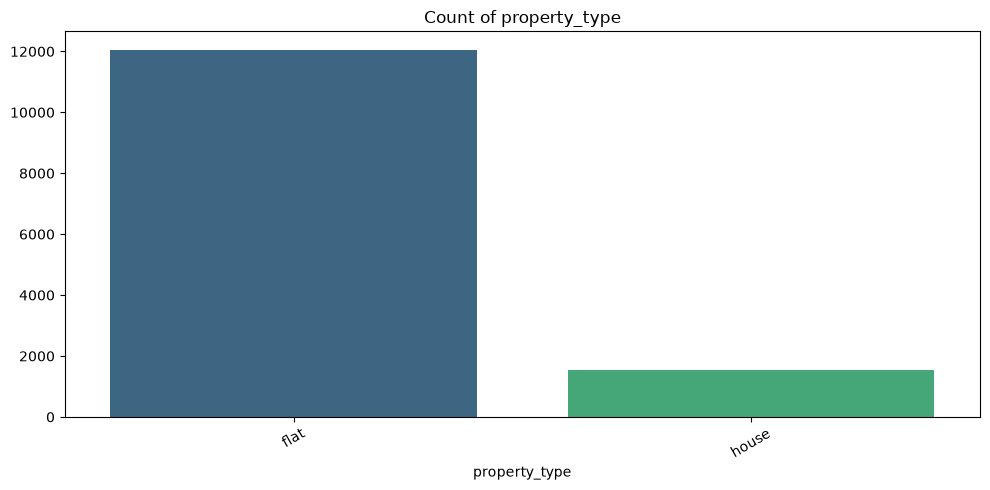

In [496]:
analyze_categorical('property_type')

In [497]:
df['property_type'].isnull().sum()

np.int64(0)

#### Observations

- Flats are in majority (88.72 percent) and there are less number of houses (11.28 percent)
- No missing values

## society

In [498]:
df['society'].value_counts()

society
independent                                           1933
shapoorji pallonji joyville gurugram                   124
emaar digihomes                                        117
ss the leaf                                            115
sobha city                                             108
dlf the ultima                                         104
la vida by tata housing                                 99
signature global park                                   97
experion windchants                                     95
tulip violet                                            93
tata primanti                                           89
godrej meridien                                         89
shree vardhman victoria                                 88
m3m golfestate                                          84
ireo skyon                                              84
bptp terra                                              83
paras dews                                      

In [499]:
df['society'].value_counts().shape

(1131,)

In [500]:
df[df['society'] != 'independent']['society'].value_counts(normalize=True).cumsum().head(74)

society
shapoorji pallonji joyville gurugram            0.010639
emaar digihomes                                 0.020678
ss the leaf                                     0.030545
sobha city                                      0.039811
dlf the ultima                                  0.048734
la vida by tata housing                         0.057229
signature global park                           0.065551
experion windchants                             0.073702
tulip violet                                    0.081682
tata primanti                                   0.089318
godrej meridien                                 0.096954
shree vardhman victoria                         0.104505
m3m golfestate                                  0.111712
ireo skyon                                      0.118919
bptp terra                                      0.126040
paras dews                                      0.133076
conscient elevate                               0.140112
signature global city 9

In [501]:
society_counts = df['society'].value_counts()

# Frequency distribution for societies
frequency_bins = {
    "Very High (>100)": (society_counts > 100).sum(),
    "High (50-100)": ((society_counts >= 50) & (society_counts <= 100)).sum(),
    "Average (10-49)": ((society_counts >= 10) & (society_counts < 50)).sum(),
    "Low (2-9)": ((society_counts > 1) & (society_counts < 10)).sum(),
    "Very Low (1)": (society_counts == 1).sum()
}
frequency_bins

{'Very High (>100)': np.int64(6),
 'High (50-100)': np.int64(53),
 'Average (10-49)': np.int64(243),
 'Low (2-9)': np.int64(341),
 'Very Low (1)': np.int64(488)}

--- society --- (unique = 1131)


,Count,Percent
society,,
independent,1933,14.23
shapoorji pallonji joyville gurugram,124,0.91
emaar digihomes,117,0.86
ss the leaf,115,0.85
sobha city,108,0.79
dlf the ultima,104,0.77
la vida by tata housing,99,0.73
signature global park,97,0.71
experion windchants,95,0.70


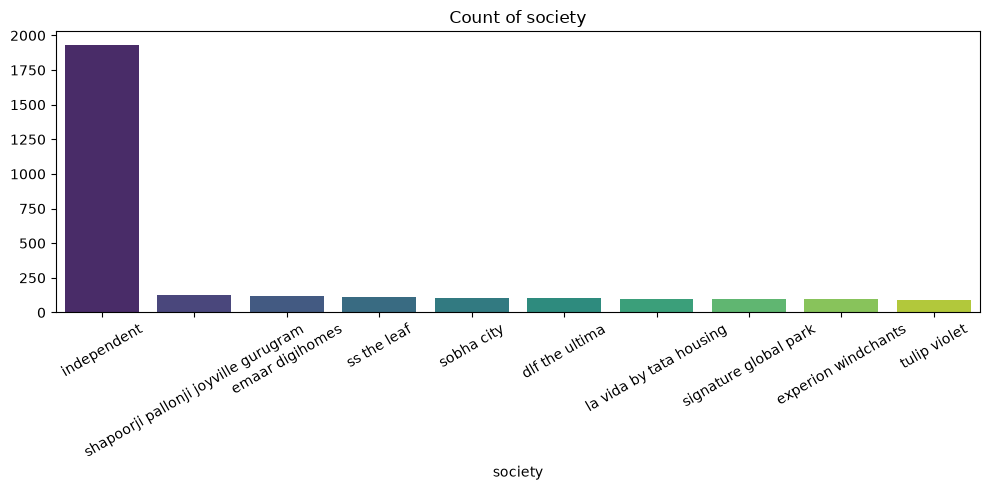

In [502]:
analyze_categorical('society', top_n= 10)

<Axes: xlabel='society'>

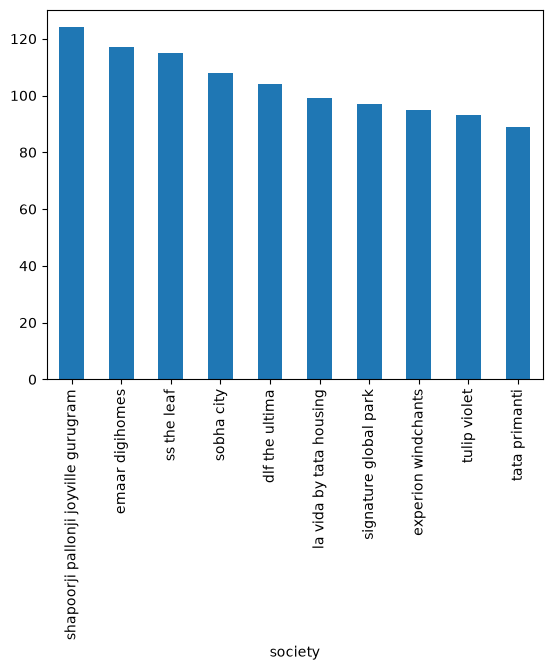

In [503]:
# top 10 socities
df[df['society'] != 'independent']['society'].value_counts().head(10).plot(kind='bar')

In [504]:
round((df[df['society'] == 'independent'].shape[0]/df.shape[0]) * 100)

14

In [505]:
df['society'].isnull().sum()

np.int64(1)

In [506]:
df[df['society'].isnull()]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
3136,flat,NaN,sector 78,0.6,3692.0,1625.0,Built Up area: 1625 (150.97 sq.m.),2,2,0,NaN,NaN,Under Construction,NaN,1625.0,NaN,0,0,0,0,0,0,0


In [507]:
# cumulative share of listings, excluding 'independent'
soc = df[df['society'] != 'independent']['society'].value_counts()
cum_share = soc.cumsum() / soc.sum()

In [508]:
cum_share

society
shapoorji pallonji joyville gurugram                  0.010639
emaar digihomes                                       0.020678
ss the leaf                                           0.030545
sobha city                                            0.039811
dlf the ultima                                        0.048734
la vida by tata housing                               0.057229
signature global park                                 0.065551
experion windchants                                   0.073702
tulip violet                                          0.081682
tata primanti                                         0.089318
godrej meridien                                       0.096954
shree vardhman victoria                               0.104505
m3m golfestate                                        0.111712
ireo skyon                                            0.118919
bptp terra                                            0.126040
paras dews                                     

In [509]:
k = (cum_share >= 0.5).values.argmax() + 1
print(f"Top {k} societies cover {cum_share.iloc[k-1]:.1%} of non-independent properties")
print(f"Remaining {len(soc) - k} societies cover the other {1 - cum_share.iloc[k-1]:.1%}")

Top 98 societies cover 50.1% of non-independent properties
Remaining 1032 societies cover the other 49.9%


#### Observations

- Around 14% properties comes under independent tag.
- There are 1131 societies. 
- The top 98 societies have 50 percent of the preperties and the rest 50 percent of the properties come under the remaining 1032 societies
    - Very High (>100): Only 6 society has more than 100 listings.
    - High (50-100): 53 societies have between 50 to 100 listings.
    - Average (10-49): 243 societies fall in this range with 10 to 49 listings each.
    - Low (2-9): 341 societies have between 2 to 9 listings.
    - Very Low (1): A significant number, 488 societies, have only 1 listing.
- 1 missing value

## sector

In [510]:
df['sector'].isnull().sum()

np.int64(0)

--- sector --- (unique = 108)


,Count,Percent
sector,,
sector 43,509,3.75
sector 65,418,3.08
sohna road,414,3.05
sector 102,361,2.66
sector 50,325,2.39
sector 25,316,2.33
sector 48,309,2.27
sector 49,308,2.27
sector 92,301,2.22


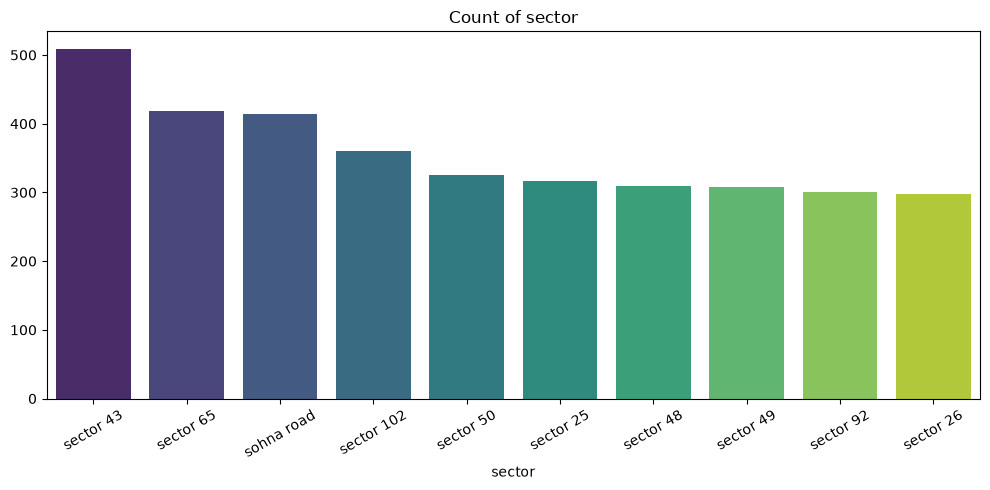

In [511]:
## top 10 sectors
analyze_categorical(col= 'sector', top_n= 10)

In [512]:
# Frequency distribution for sectors
sector_counts = df['sector'].value_counts()

sector_frequency_bins = {
    "Very High (>100)": (sector_counts > 100).sum(),
    "High (50-100)": ((sector_counts >= 50) & (sector_counts <= 100)).sum(),
    "Average (10-49)": ((sector_counts >= 10) & (sector_counts < 50)).sum(),
    "Low (2-9)": ((sector_counts > 1) & (sector_counts < 10)).sum(),
    "Very Low (1)": (sector_counts == 1).sum()
}

sector_frequency_bins

{'Very High (>100)': np.int64(54),
 'High (50-100)': np.int64(22),
 'Average (10-49)': np.int64(28),
 'Low (2-9)': np.int64(4),
 'Very Low (1)': np.int64(0)}

#### Observations

- There are a total of 106 unique sectors in the dataset.
- Frequency distribution of sectors:
    - Very High (>100): A majority, 54 sectors have more than 100 listings.
    - High (50-100): 22 sectors have between 50 to 100 listings.
    - Average (10-49): 28 sectors, fall in this range with 10 to 49 listings each.
    - Low (2-9): 4 sectors have between 2 to 9 listings.
    - Very Low (1): Interestingly, there are no sectors with only 1 listing.
- There is no missing value.

## price

In [513]:
df['price'].isnull().sum()

np.int64(28)

--- price ---
Mean=3.11 | Median=2.05 | Mode=2.0 | Std=4.91
Min=0.0 | Max=290.0 | Skew=25.70 | Kurtosis=1243.59
IQR outliers: 1052 (7.74%)


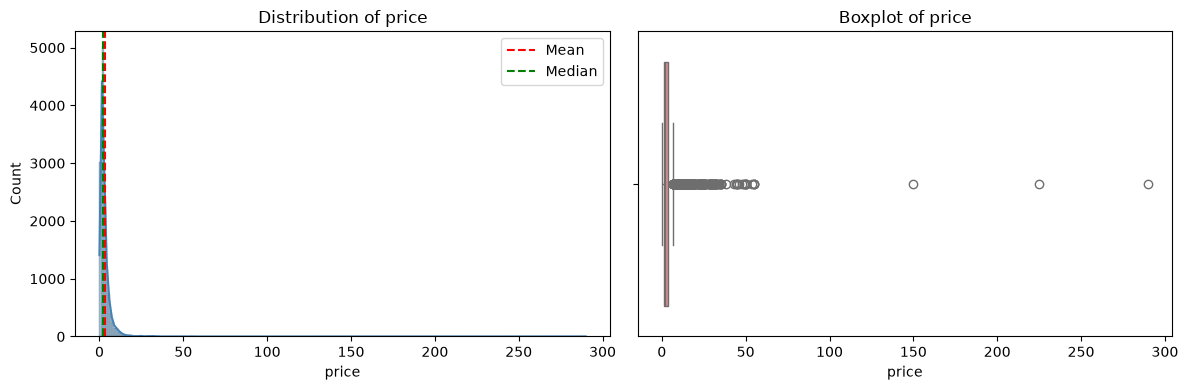

In [514]:
analyze_numeric(col= 'price')

In [515]:
df['price'].describe()

count    13561.000000
mean         3.109723
std          4.905224
min          0.000000
25%          1.300000
50%          2.050000
75%          3.550000
max        290.000000
Name: price, dtype: float64

In [516]:
df[df['price'] == 290]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
12108,flat,independent floor at dlf city,sector 24,290.0,2071428.0,1400.0,Built Up area: 2430 (225.75 sq.m.)Carpet area: 1400 sq.ft. (130.06 sq.m.),4,4,3,2.0,NaN,New Property,NaN,2430.0,1400.0,0,1,0,0,0,1,193


In [517]:
df[df['price'] == 0]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
4286,house,ansal heights,sector 92,0.0,9.0,0.0,Plot area 555.56(464.52 sq.m.)Built Up area: 4500 sq.ft. (418.06 sq.m.)Carpet area: 4200 sq.ft. (390.19 sq.m.),4,4,3+,15.0,East,Relatively New,NaN,4500.0,4200.0,0,0,0,0,0,0,50
12649,flat,independent,sector 31,0.0,30.0,0.0,Carpet area: 1500 (139.35 sq.m.),2,2,2,2.0,North,Old Property,NaN,NaN,1500.0,1,0,0,0,0,2,21


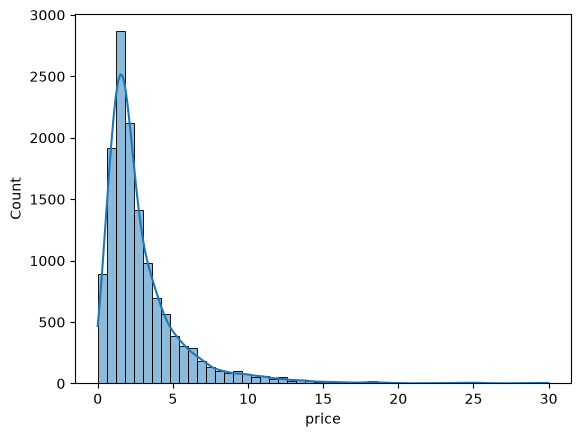

In [518]:
sns.histplot(df.loc[df['price'] <= 30, 'price'], kde=True, bins=50)
plt.show()

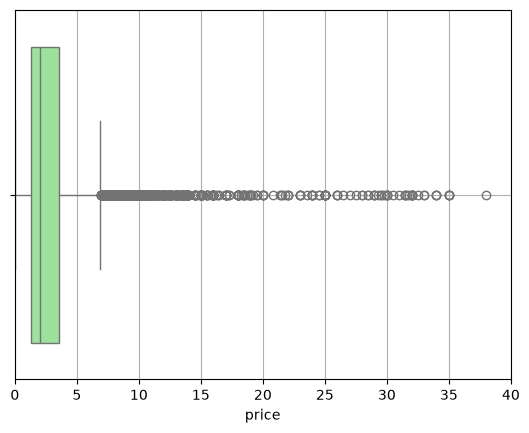

In [519]:
sns.boxplot(x=df['price'], color='lightgreen')
plt.xlim(0, 40)
plt.grid()
plt.show()

- Descriptive Statistics:

    - Count: There are 13,561 non-missing price entries.
    - Mean Price: The average price is approximately 3.11 crores.
    - Median Price: The median (or 50th percentile) price is 2.05 crores.
    - Standard Deviation: The prices have a standard deviation of 4.90, indicating variability in the prices.
    - Range: Prices range from a minimum of 0 crores to a maximum of 290 crores.
    - IQR: The interquartile range (difference between 75th and 25th percentile) is from 1.3 crores to 3.55 crores.


- Visualizations:

    - The histogram is heavily right-skewed.
    - Most listings are under 5 crore, with a long tail of very expensive properties.
 
- Missing Values:

    - There are 28 missing values in the price column.

In [520]:
# Skewness and Kurtosis
skewness = round(df['price'].skew(), 2)
kurtosis = round(df['price'].kurt(), 2)

print(f'The Skewness is: {skewness}')
print(f'The Kurtosis is: {kurtosis}')

The Skewness is: 25.7
The Kurtosis is: 1243.59


**Skewness**: The price distribution has a skewness of approximately 25.7, indicating a positive skew. This means that the distribution tail is skewed to the right, which aligns with our observation from the histogram where most properties have prices on the lower end with a few high-priced properties.

**Kurtosis**: The kurtosis value is approximately 1243.59. A kurtosis value greater than 3 indicates a distribution with heavier tails and more outliers compared to a normal distribution.

In [521]:
## Quantile Analysis
quantiles = df['price'].quantile([0.01, 0.05, 0.95, 0.99])

print(f'Quantiles:\n{quantiles}')

Quantiles:
0.01     0.27
0.05     0.50
0.95     8.50
0.99    17.00
Name: price, dtype: float64


Quantile Analysis:

- 1% Quantile: Only 1% of properties are priced below 0.27 crores.
- 5% Quantile: 5% of properties are priced below 0.50 crores.
- 95% Quantile: 95% of properties are priced below 8.5 crores.
- 99% Quantile: 99% of properties are priced below 17 crores, indicating that very few properties are priced above this value.

In [522]:
# Identify potential outliers using IQR method
Q1 = df['price'].describe()['25%']
Q3 = df['price'].describe()['75%']
IQR = Q3 - Q1

print(f'IQR: {IQR}')

IQR: 2.25


In [523]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

Lower Bound: -2.075, Upper Bound: 6.925


In [524]:
outliers = df[(df['price'] < lower_bound) | (df['price'] > upper_bound)]
print(f"The Number of Outliers: {outliers.shape[0]}")

The Number of Outliers: 1052


In [525]:
outliers['price'].describe()

count    1052.000000
mean       12.577890
std        13.691308
min         6.950000
25%         8.000000
50%         9.600000
75%        12.500000
max       290.000000
Name: price, dtype: float64

Outliers Analysis (using IQR method):

- Based on the IQR method, there are 1052 properties considered as outliers.
- These outliers have an average price of approximately 12.57 crores.
- The range for these outliers is from 6.95 crores to 290 crores.

<Axes: xlabel='price'>

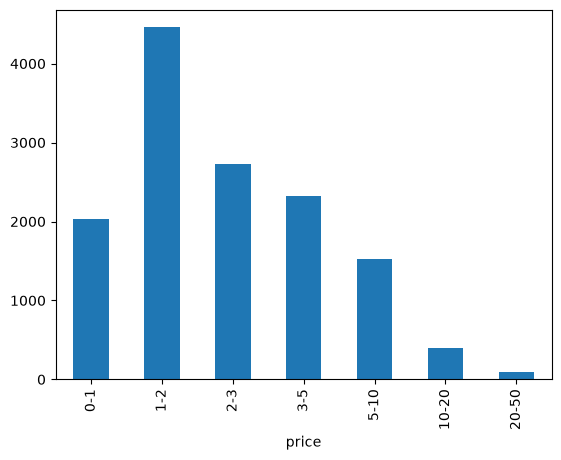

In [526]:
## price binning
bins = [0, 1, 2, 3, 5, 10, 20, 50]
bin_labels = ["0-1", "1-2", "2-3", "3-5", "5-10", "10-20", "20-50"]
pd.cut(df['price'], bins=bins, labels=bin_labels, right=False).value_counts().sort_index().plot(kind='bar')

- The 1-2 crore bin is the largest (4,459), followed by 2-3 crore (2,727) and 3-5 crore (2,329).
- Only 90 listings fall in 20-50 crore. Above 5 crore, counts fall away quickly.

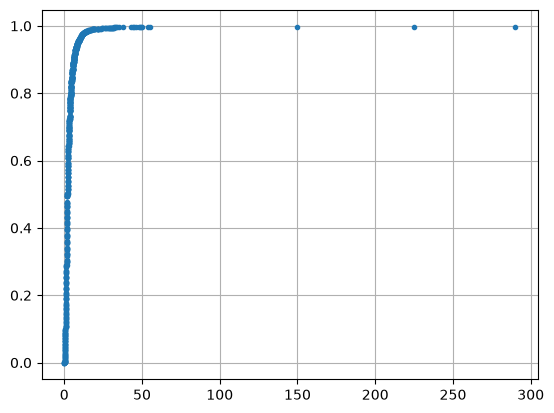

In [527]:
# ecdf plot
ecdf = df['price'].value_counts().sort_index().cumsum() / len(df['price'])
plt.plot(ecdf.index, ecdf, marker='.', linestyle='none')
plt.grid()

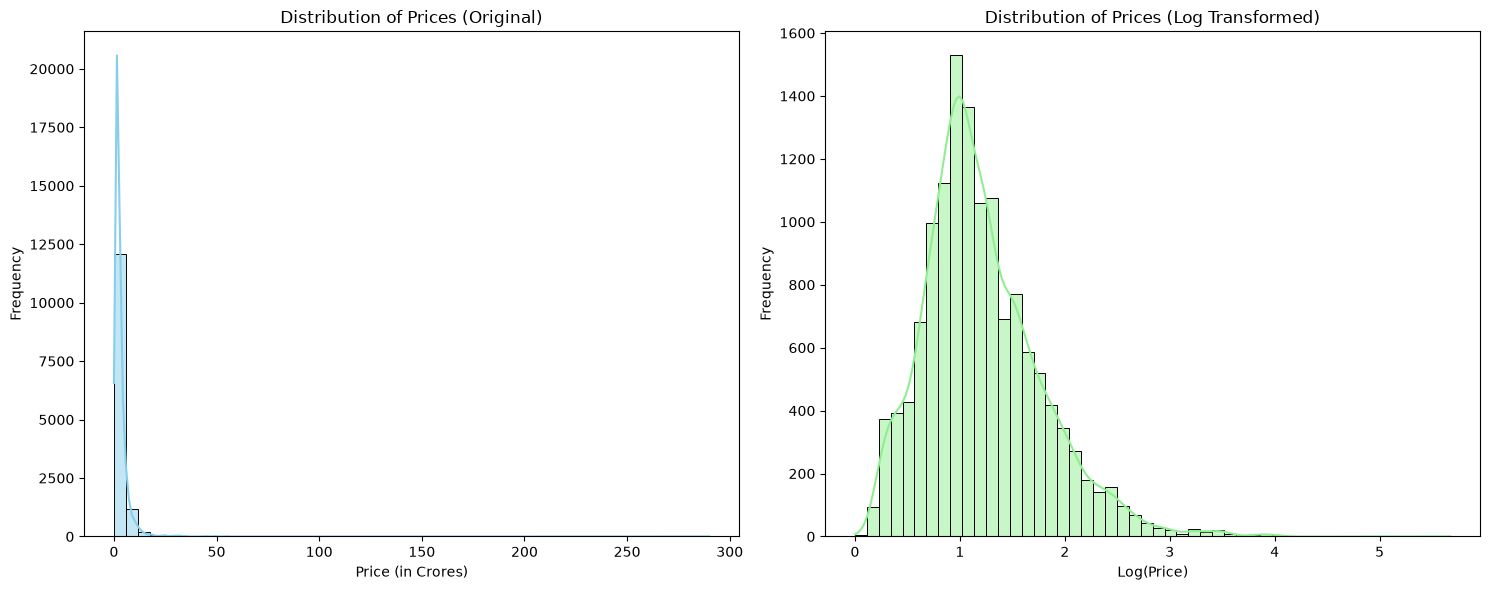

In [528]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.histplot(df['price'], kde=True, bins=50, color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.histplot(np.log1p(df['price']), kde=True, bins=50, color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

np.log1p(x): This function computes the natural logarithm of 1+x. 
It's designed to provide more accurate results for values of x that are very close to zero.

Using np.log1p helps in transforming the price column while ensuring that any value (including zero, if present) is handled appropriately. When we need to reverse the transformation, we can use np.expm1 which computes e^x-1

In [529]:
skewness = np.log1p(df['price']).skew()
kurtosis = np.log1p(df['price']).kurt()

print(f'The Skewness after log transform is: {skewness}')
print(f'The Kurtosis after log transform is: {kurtosis}')

The Skewness after log transform is: 0.991380306041542
The Kurtosis after log transform is: 2.034056063907548


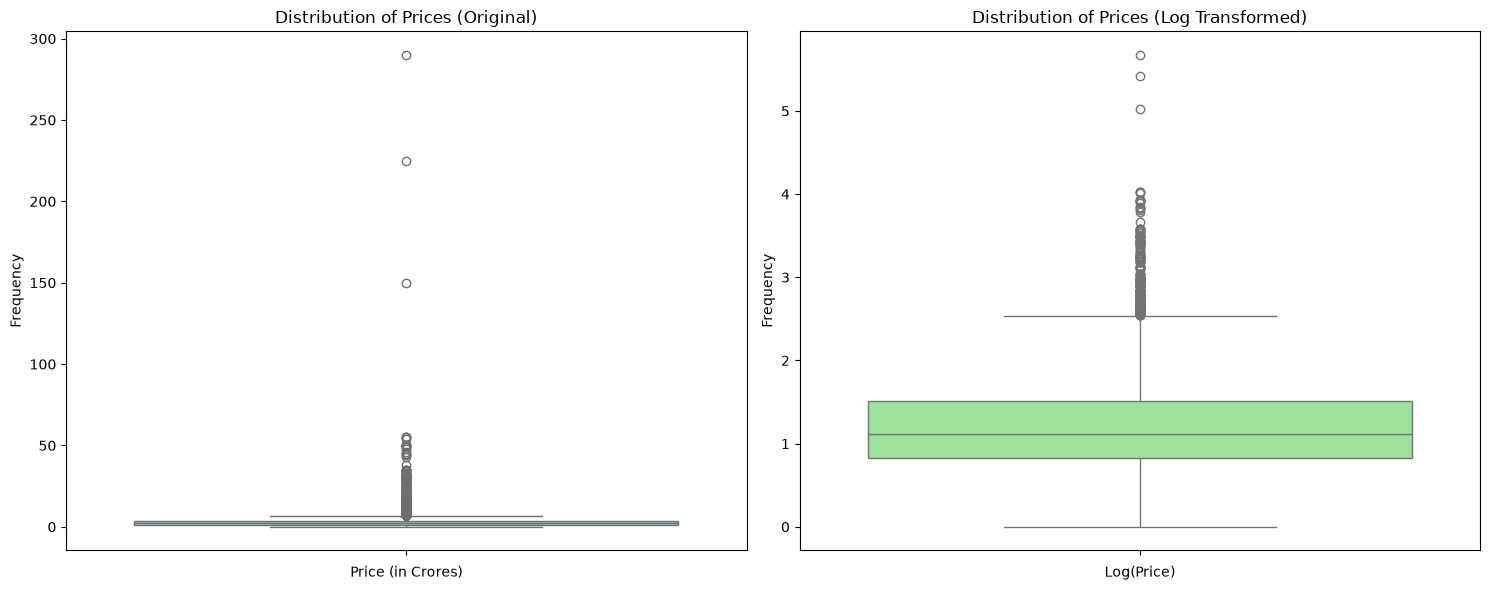

In [530]:
plt.figure(figsize=(15, 6))

# Distribution plot without log transformation
plt.subplot(1, 2, 1)
sns.boxplot(df['price'], color='skyblue')
plt.title('Distribution of Prices (Original)')
plt.xlabel('Price (in Crores)')
plt.ylabel('Frequency')

# Distribution plot with log transformation
plt.subplot(1, 2, 2)
sns.boxplot(np.log1p(df['price']), color='lightgreen')
plt.title('Distribution of Prices (Log Transformed)')
plt.xlabel('Log(Price)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [531]:
df[df['price'] >= 59]

,property_type,society,sector,price,price_per_sqft,area,areaWithType,bedRoom,bathroom,balcony,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
4176,flat,dlf the camellias,sector 42,150.0,88235.0,17000.0,Super Built up area 17000(1579.35 sq.m.),10,11,3+,38.0,NaN,New Property,17000.0,NaN,NaN,0,1,0,0,0,2,97
7930,flat,dlf garden city floors,sector 92,225.0,1190476.0,1890.0,Carpet area: 1890 (175.59 sq.m.),4,4,3+,4.0,North-East,New Property,NaN,NaN,1890.0,0,0,0,0,0,0,60
12108,flat,independent floor at dlf city,sector 24,290.0,2071428.0,1400.0,Built Up area: 2430 (225.75 sq.m.)Carpet area: 1400 sq.ft. (130.06 sq.m.),4,4,3,2.0,NaN,New Property,NaN,2430.0,1400.0,0,1,0,0,0,1,193


## price_per_sqft

In [532]:
df['price_per_sqft'].isnull().sum()

np.int64(28)

In [533]:
df['price_per_sqft'].describe()

count    1.356100e+04
mean     1.408999e+04
std      3.038487e+04
min      4.000000e+00
25%      8.009000e+03
50%      1.078900e+04
75%      1.474700e+04
max      2.071428e+06
Name: price_per_sqft, dtype: float64

--- price_per_sqft ---
Mean=14089.99 | Median=10789.00 | Mode=10000.0 | Std=30384.87
Min=4.0 | Max=2071428.0 | Skew=42.89 | Kurtosis=2496.19
IQR outliers: 980 (7.21%)


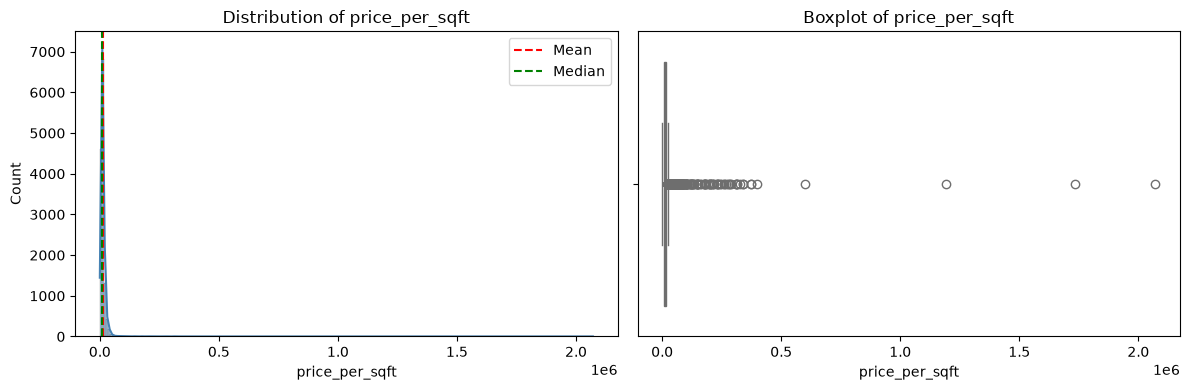

In [534]:
analyze_numeric(col= 'price_per_sqft')

<Axes: xlabel='price_per_sqft', ylabel='Count'>

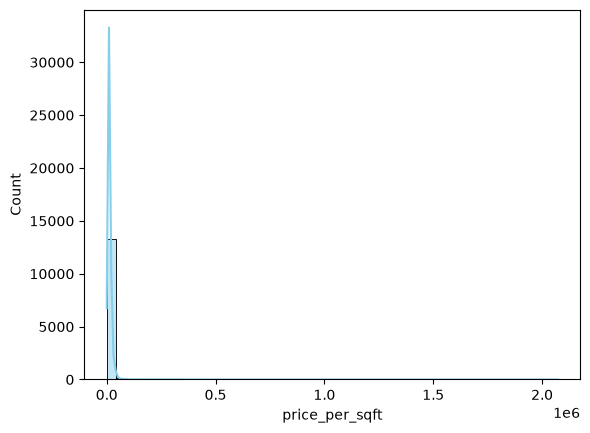

In [535]:
sns.histplot(df['price_per_sqft'], bins=50, color='skyblue', kde=True)

<Axes: ylabel='price_per_sqft'>

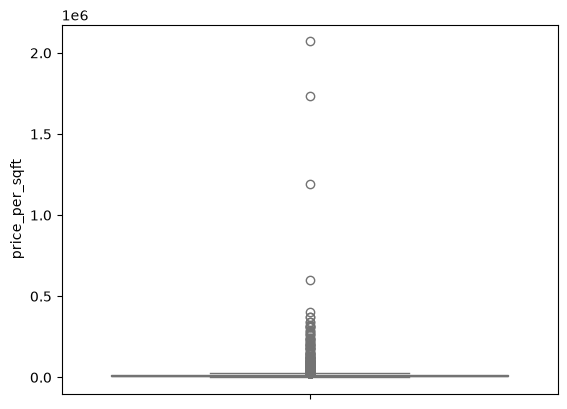

In [536]:
sns.boxplot(df['price_per_sqft'], color='lightgreen')

### Observations
- 28 missing values.
- The median is ~10,789 per sq ft and the mean is ~14,090. The IQR is ~8,009 to ~14,747.
- The max is ~2,071,428, which is clearly erroneous. The min is 4, which is also suspect.
- The skewness of ~42.9 is extremely right-skewed, so treat the extremes as data errors.

## bedRoom

--- bedRoom ---
Mean=3.35 | Median=3.00 | Mode=3 | Std=1.51
Min=1 | Max=36 | Skew=5.02 | Kurtosis=49.75
IQR outliers: 681 (5.01%)


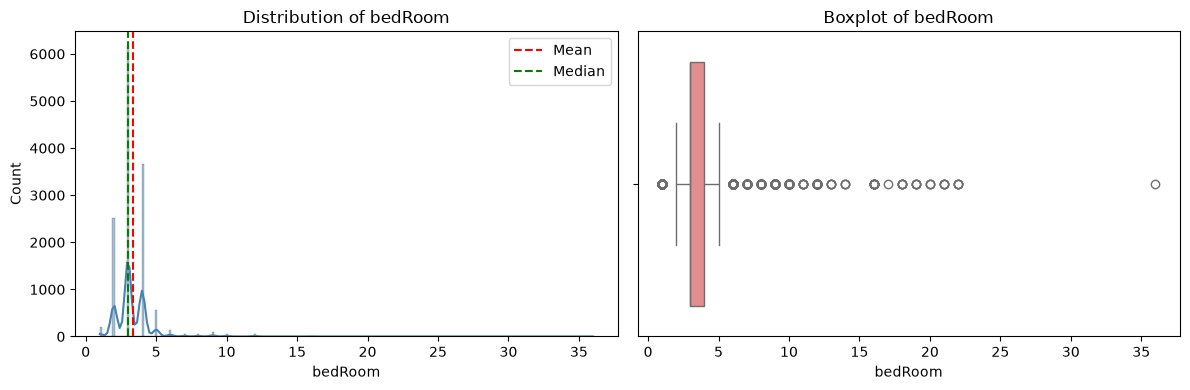

In [537]:
analyze_numeric(col= 'bedRoom')

<Axes: xlabel='bedRoom'>

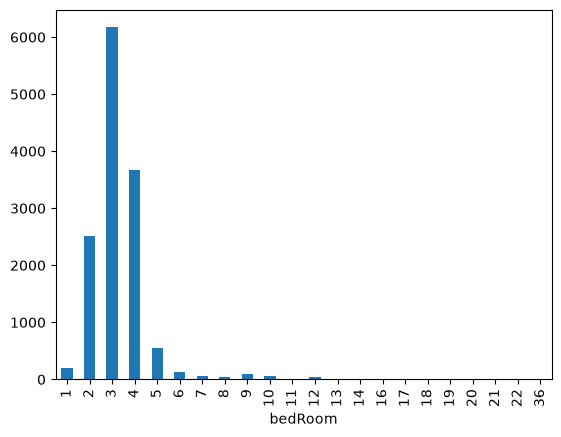

In [538]:
df['bedRoom'].value_counts().sort_index().plot(kind='bar')

In [539]:
df['bedRoom'].isnull().sum()

np.int64(0)

<Axes: >

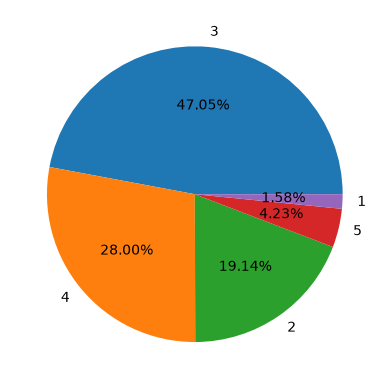

In [540]:
df['bedRoom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

### Observations
- There are no missing values.
- 3 BHK is the most common (6,171 listings), followed by 4 (3,672) and 2 (2,510).
- The max is 36, which is a clear outlier.

## bathroom

In [541]:
df['bathroom'].isnull().sum()

np.int64(0)

--- bathroom ---
Mean=3.52 | Median=3.00 | Mode=3 | Std=1.63
Min=1 | Max=36 | Skew=3.93 | Kurtosis=35.77
IQR outliers: 1082 (7.96%)


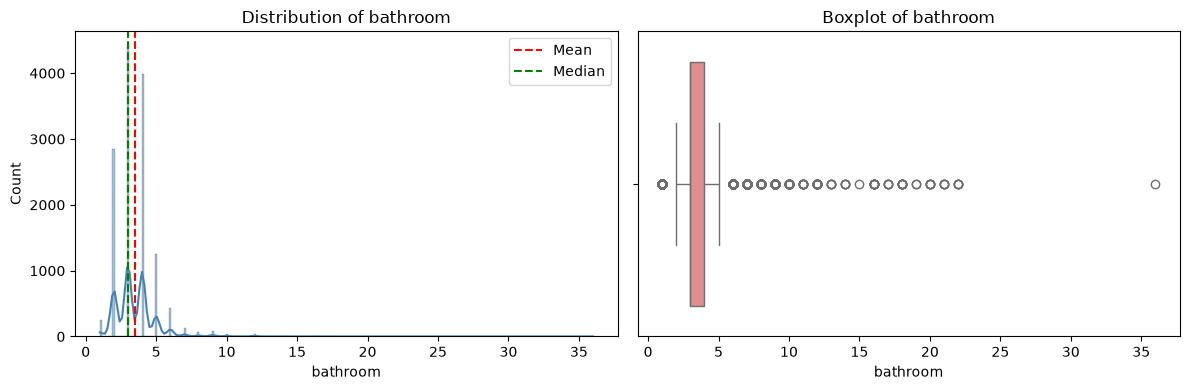

In [542]:
analyze_numeric(col= 'bathroom')

<Axes: xlabel='bathroom'>

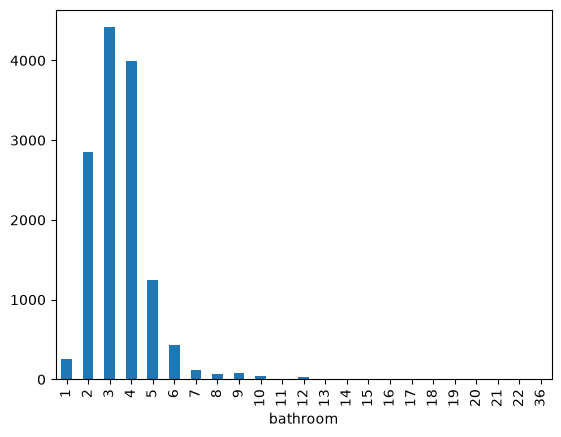

In [543]:
df['bathroom'].value_counts().sort_index().plot(kind='bar')

<Axes: >

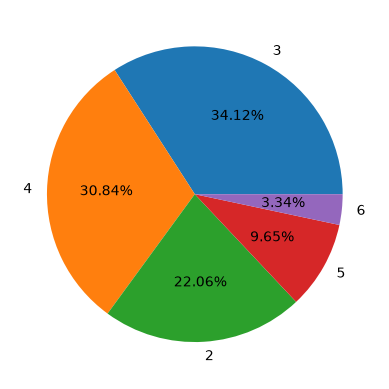

In [544]:
df['bathroom'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

### Observations
- There are no missing values.
- The median is 3 bathrooms, and the max is 36.

## balcony

In [545]:
df['balcony'].isnull().sum()

np.int64(0)

<Axes: xlabel='balcony'>

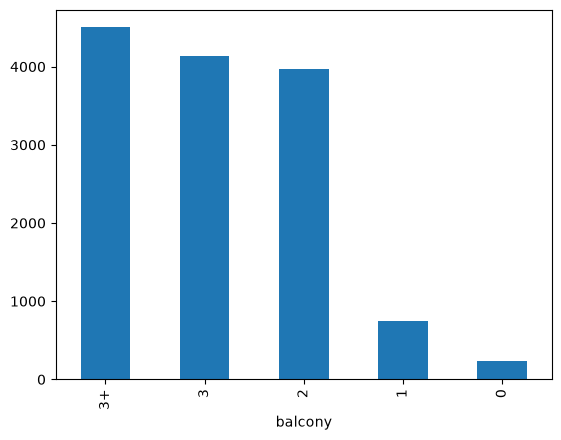

In [546]:
df['balcony'].value_counts().plot(kind='bar')

<Axes: >

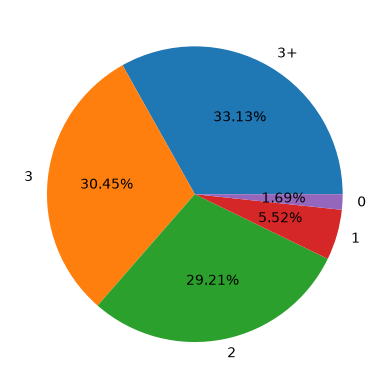

In [547]:
df['balcony'].value_counts(normalize=True).head().plot(kind='pie',autopct='%0.2f%%')

### Observations
- `balcony` is stored as text, and there are no missing values.
- `3+` has the most listings (4,502), then `3` (4,138), `2` (3,970), `1` (750) and `0` (229).

## floorNum

In [548]:
df.iloc[:,10:].head()

,floorNum,facing,agePossession,super_built_up_area,built_up_area,carpet_area,study room,servant room,store room,pooja room,others,furnishing_type,luxury_score
0,3.0,East,Moderately Old,NaN,2520.0,NaN,1,1,0,1,0,1,104
1,6.0,South,Relatively New,1900.0,NaN,1240.04,0,1,0,0,0,1,146
2,6.0,North-West,Relatively New,2860.0,NaN,NaN,0,0,0,0,0,1,107
3,4.0,West,Relatively New,1741.0,NaN,NaN,0,0,1,0,0,0,149
4,10.0,South-East,Relatively New,1380.0,1310.0,900.00,0,0,0,0,1,0,220


In [549]:
df['floorNum'].isnull().sum()

np.int64(22)

In [550]:
df['floorNum'].describe()

count    13567.000000
mean         6.840348
std          6.255543
min          0.000000
25%          2.000000
50%          5.000000
75%         10.000000
max         51.000000
Name: floorNum, dtype: float64

--- floorNum ---
Mean=6.84 | Median=5.00 | Mode=2.0 | Std=6.26
Min=0.0 | Max=51.0 | Skew=1.69 | Kurtosis=4.05
IQR outliers: 370 (2.72%)


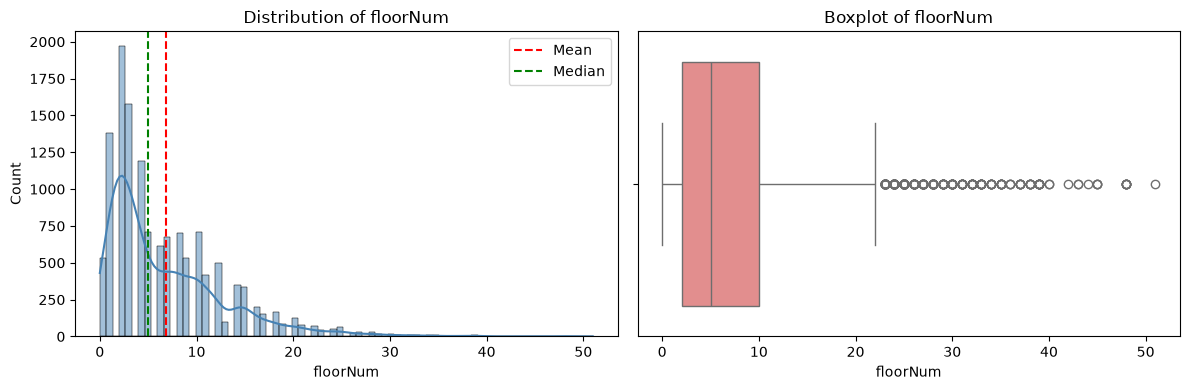

In [551]:
analyze_numeric(col= 'floorNum')

### Observations
- 22 missing values.
- The median is floor 5 and the mean is ~6.8. The IQR is floors 2 to 10, and the max is 51.
- Skewness is ~1.69, so the distribution is right-skewed.
- Most properties are on lower floors, and high floors (above ~20) show up as outliers in the boxplot.

## facing

In [552]:
df['facing'].value_counts(dropna= False)

facing
North-East    3985
East          2929
NaN           2190
North         1747
West           847
North-West     543
South-East     521
South          460
South-West     367
Name: count, dtype: int64

--- facing --- (unique = 8)


,Count,Percent
facing,,
North-East,3985,34.96
East,2929,25.70
North,1747,15.33
West,847,7.43
North-West,543,4.76
South-East,521,4.57
South,460,4.04
South-West,367,3.22


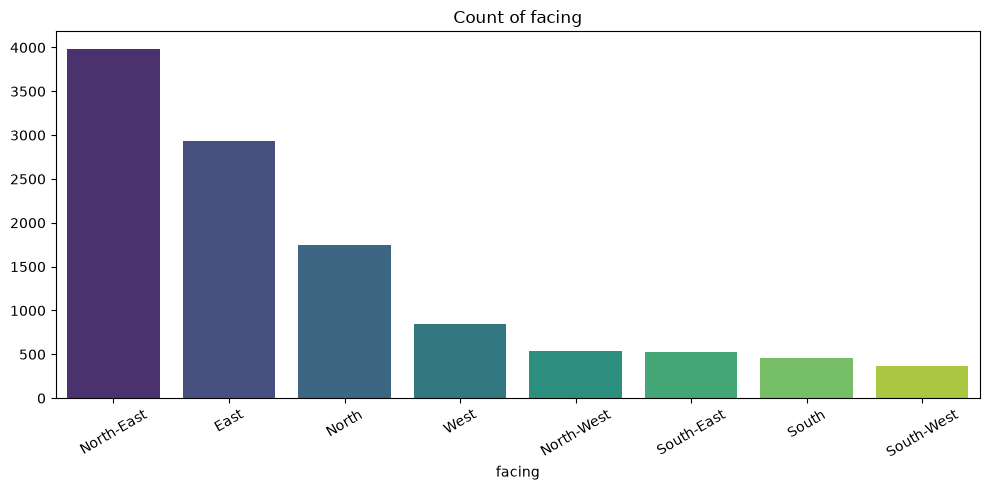

In [553]:
analyze_categorical(col= 'facing')

In [554]:
df['facing'].isnull().sum()

np.int64(2190)

### Observations
- 2,190 missing values (~16%).
- North-East is the most common (3,985), then East (2,929) and North (1,747).

## agePossession

In [555]:
df['agePossession'].isnull().sum()

np.int64(0)

--- agePossession --- (unique = 6)


,Count,Percent
agePossession,,
Relatively New,5009,36.86
New Property,3245,23.88
Moderately Old,2036,14.98
Under Construction,2036,14.98
Old Property,948,6.98
Undefined,315,2.32


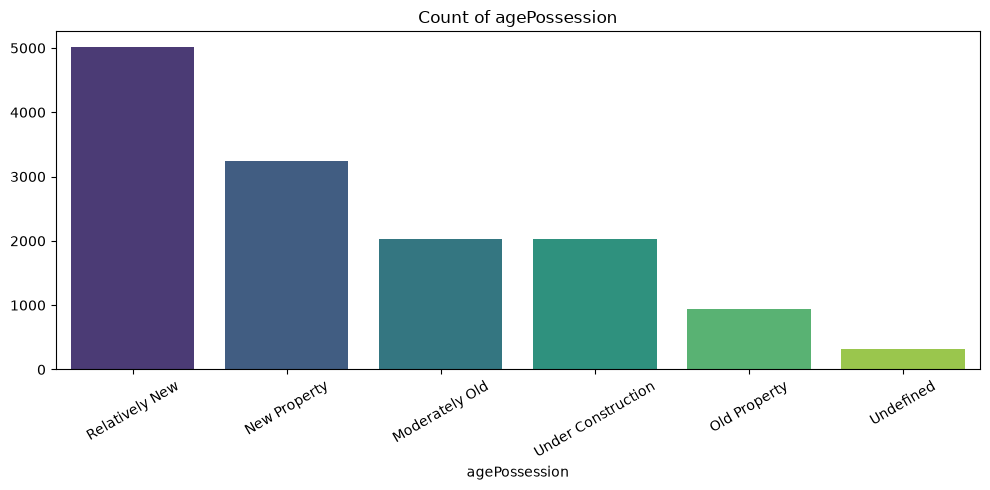

In [556]:
analyze_categorical(col= 'agePossession')

### Observations
- No missing values, but 315 entries are Undefined.
- Relatively New is the largest category (5,009), then New Property (3,245).
- Moderately Old and Under Construction each have 2,036, and Old Property has 948.

## super_built_up_area

In [558]:
df['super_built_up_area'].isnull().sum()

np.int64(5382)

In [559]:
df['super_built_up_area'].describe()

count      8207.000000
mean       2272.216309
std        3077.566706
min          89.000000
25%        1578.000000
50%        1997.000000
75%        2588.790000
max      258879.000000
Name: super_built_up_area, dtype: float64

<Axes: xlabel='super_built_up_area', ylabel='Count'>

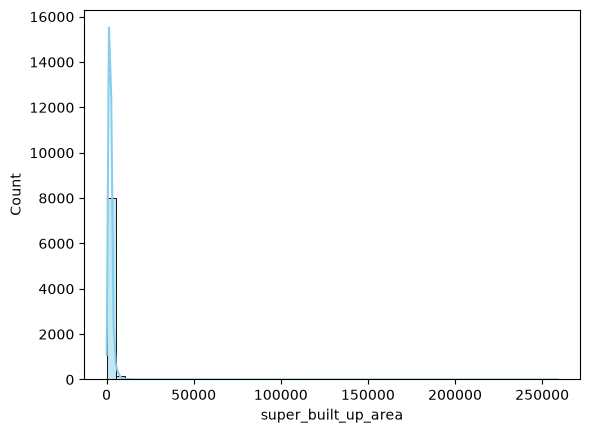

In [569]:
sns.histplot(df['super_built_up_area'].dropna(), bins=50, color='skyblue', kde=True)

<Axes: ylabel='super_built_up_area'>

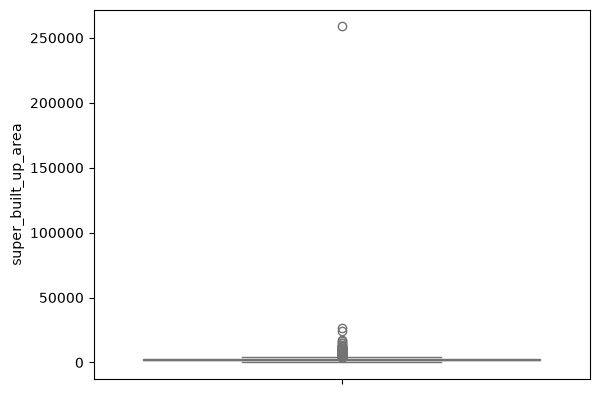

In [570]:
sns.boxplot(df['super_built_up_area'].dropna(), color='lightgreen')

In [572]:
df['super_built_up_area'].describe()

count      8207.000000
mean       2272.216309
std        3077.566706
min          89.000000
25%        1578.000000
50%        1997.000000
75%        2588.790000
max      258879.000000
Name: super_built_up_area, dtype: float64

### Observations
- 5,382 missing values (~40%).
- The median is ~1,997 sq ft and the IQR is ~1,578 to ~2,589.
- The max is 258,879, which is almost certainly a data error.

## built up area

In [573]:
df['built_up_area'].isnull().sum()

np.int64(8806)

In [574]:
df['built_up_area'].describe()

count      4783.000000
mean       2591.203393
std       11193.539876
min          30.000000
25%        1405.000000
50%        1900.000000
75%        2700.000000
max      737147.000000
Name: built_up_area, dtype: float64

<Axes: xlabel='built_up_area', ylabel='Count'>

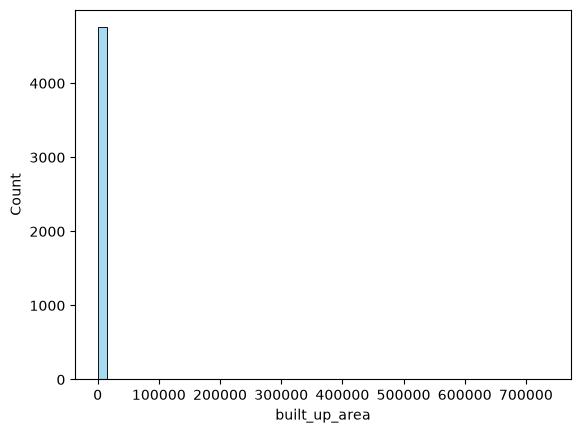

In [575]:
sns.histplot(df['built_up_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='built_up_area'>

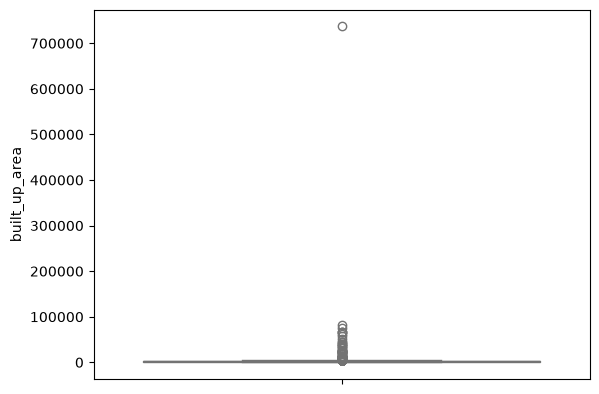

In [576]:
sns.boxplot(df['built_up_area'].dropna(), color='lightgreen')

### Observations
- 8,806 missing values (~65%), so it is the sparsest area column.
- The median is ~1,900 sq ft and the IQR is ~1,405 to ~2,700.
- The max is 737,147, an extreme data error. It is a larger problem than in the old data.

## carpet_area

In [577]:
df['carpet_area'].isnull().sum()

np.int64(5610)

In [578]:
df['carpet_area'].describe()

count      7979.000000
mean       2589.140738
std       18783.641682
min          15.000000
25%        1150.000000
50%        1600.000000
75%        2200.000000
max      607936.000000
Name: carpet_area, dtype: float64

<Axes: xlabel='carpet_area', ylabel='Count'>

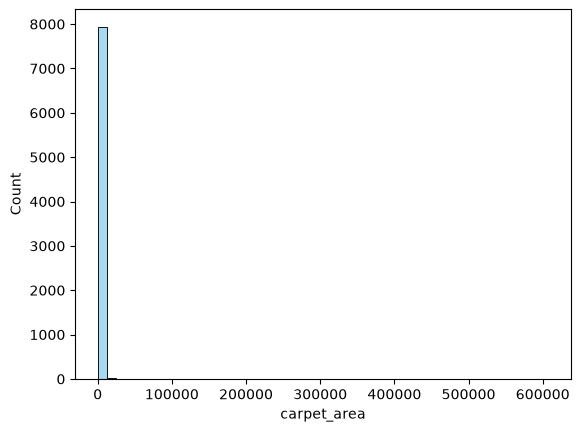

In [579]:
sns.histplot(df['carpet_area'].dropna(), bins=50, color='skyblue', kde=False)

<Axes: ylabel='carpet_area'>

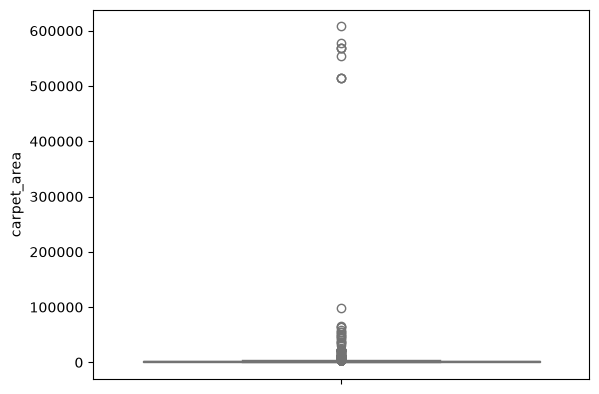

In [580]:
sns.boxplot(df['carpet_area'].dropna(), color='lightgreen')

### Observations
- 5,610 missing values (~41%).
- The median is ~1,600 sq ft and the IQR is ~1,150 to ~2,200.
- The max is 607,936, again a data error.
- The three area columns overlap: a listing usually reports only one of them. The missing values are therefore structural and can be filled from areaWithType or area.

## additional_rooms

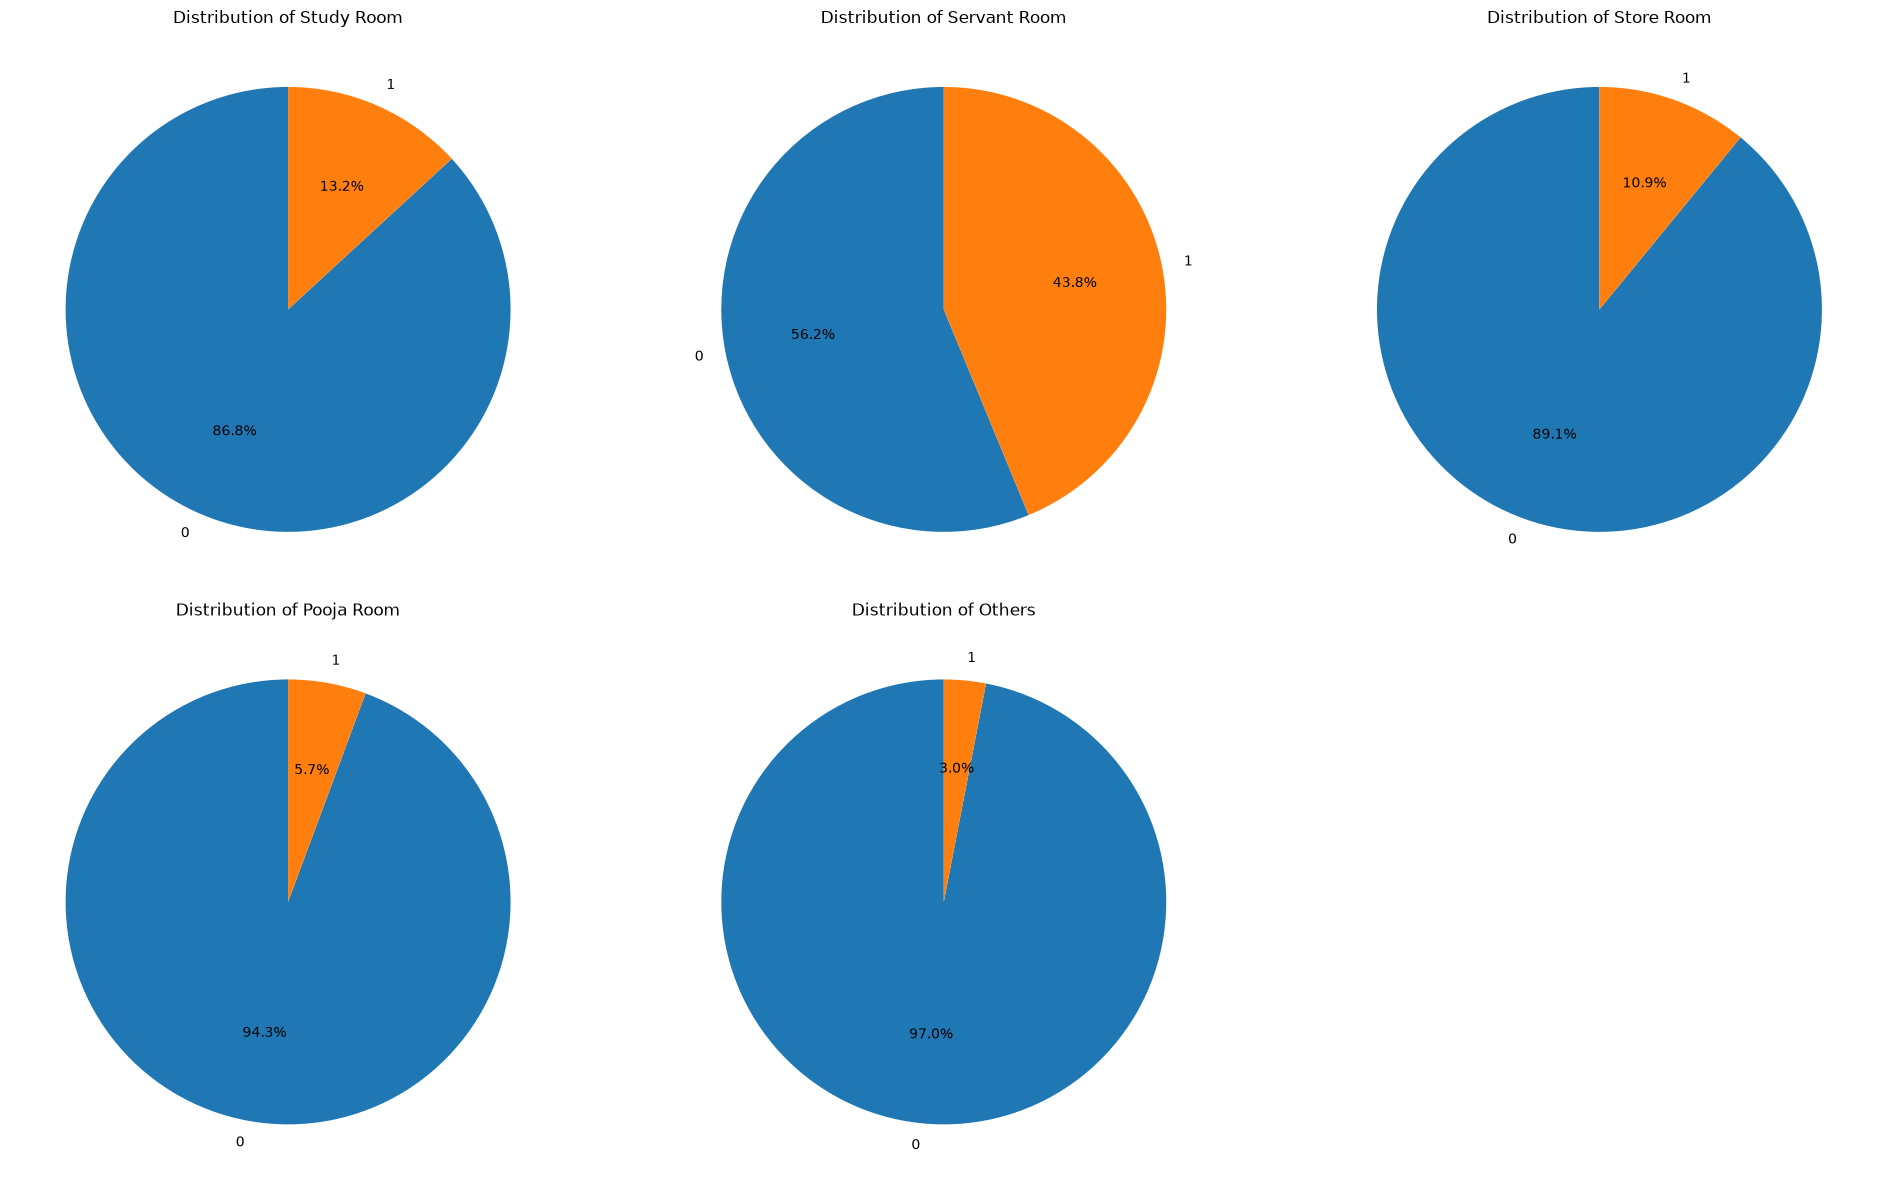

In [581]:
plt.figure(figsize=(20, 12))

# Create a subplot of pie charts for each room type
for idx, room in enumerate(['study room','servant room','store room','pooja room','others'], 1):
    ax = plt.subplot(2, 3, idx)
    df[room].value_counts().plot.pie(autopct='%1.1f%%', startangle=90, ax=ax)
    plt.title(f'Distribution of {room.title()}')
    plt.ylabel('')

plt.tight_layout()
plt.show()

### Observations
- Servant room is present in ~44% of listings (5,948).
- Study room is present in ~13% (1,788), store room in ~11% (1,486), pooja room in ~6% (770) and others in ~3% (414).

## furnishing_type

In [582]:
df['furnishing_type'].value_counts()

furnishing_type
0    6312
1    5820
2    1457
Name: count, dtype: int64

<Axes: >

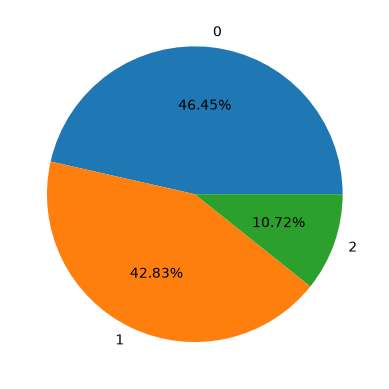

In [583]:
df['furnishing_type'].value_counts().plot(kind='pie',autopct='%0.2f%%')

### Observations
- Unfurnished (6,312, ~46%) and semifurnished (5,820, ~43%) dominate. Fully furnished is ~11% (1,457).
- The 0/1/2 to label mapping is an assumption. Check it against your data dictionary.

## luxury_score

In [584]:
df['luxury_score'].isnull().sum()

np.int64(0)

In [585]:
df['luxury_score'].describe()

count    13589.000000
mean       118.368239
std         67.924212
min          0.000000
25%         57.000000
50%        115.000000
75%        176.000000
max        236.000000
Name: luxury_score, dtype: float64

<Axes: xlabel='luxury_score', ylabel='Count'>

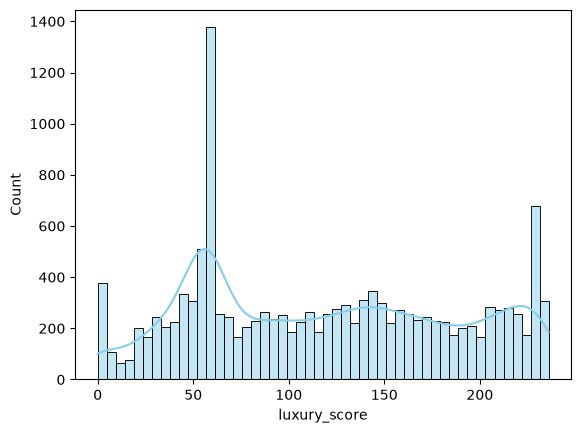

In [586]:
sns.histplot(df['luxury_score'], bins=50, color='skyblue', kde=True)

<Axes: ylabel='luxury_score'>

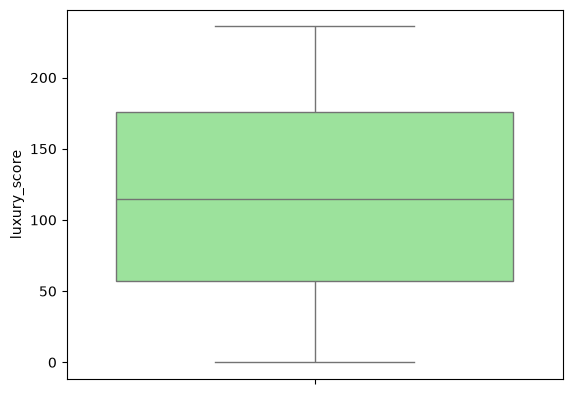

In [587]:
sns.boxplot(df['luxury_score'], color='lightgreen')

### Observations
- No missing values.
- Scores range from 0 to 236. The mean is ~118 and the median is ~115.
- The IQR is ~57 to ~176, so the spread is wide.
- Skewness is ~0.14 and kurtosis is ~-1.2, which means a flat, broad distribution with no real outliers.